# Phase 2d: Baseline IDS - Decision Tree
**Adversarial ML for Intrusion Detection Systems (CICIDS2017)**

Trains on the **balanced** training set and evaluates on the **untouched** validation and test sets.
Run Phase 1 and Phase 1b first (other Phase 2 notebooks are optional, for the comparison table).

## Step 0: Imports and settings

In [1]:
import os, json, time
import numpy as np
import joblib
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_auc_score,
                             roc_curve, classification_report)

DATA_DIR = "data/processed"
MODEL_DIR = "models"
RESULT_DIR = "results"
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

# Fail early with a clear message if the data is not where expected
needed = ["X_train_bal.npy", "y_train_bal_binary.npy", "X_val.npy", "y_val_binary.npy",
          "X_test.npy", "y_test_binary.npy", "feature_names.joblib"]
missing = [f for f in needed if not os.path.exists(os.path.join(DATA_DIR, f))]
if missing:
    raise FileNotFoundError(f"Missing in '{os.path.abspath(DATA_DIR)}': {missing}. "
                            "Run Phase 1 and Phase 1b, or fix DATA_DIR.")
print("Setup done, all data files found")

Setup done, all data files found


## Step 1: Load data

In [2]:
X_train = np.load(f"{DATA_DIR}/X_train_bal.npy")
y_train = np.load(f"{DATA_DIR}/y_train_bal_binary.npy")
X_val   = np.load(f"{DATA_DIR}/X_val.npy");  y_val  = np.load(f"{DATA_DIR}/y_val_binary.npy")
X_test  = np.load(f"{DATA_DIR}/X_test.npy"); y_test = np.load(f"{DATA_DIR}/y_test_binary.npy")
feature_names = joblib.load(f"{DATA_DIR}/feature_names.joblib")

for n, X, y in [("train (balanced)", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
    print(f"{n:17s} X={X.shape}  attack ratio={y.mean():.3f}")

train (balanced)  X=(694088, 70)  attack ratio=0.712
val               X=(378120, 70)  attack ratio=0.169
test              X=(378120, 70)  attack ratio=0.169


## Step 2: Train the Decision Tree
Settings follow the reference paper: Gini criterion, best splitter, no depth limit.

In [3]:
dt = DecisionTreeClassifier(criterion="gini", splitter="best", max_depth=None, random_state=42)

t0 = time.time()
dt.fit(X_train, y_train)
train_time = time.time() - t0
print(f"Training time: {train_time:.1f} s")
print(f"Tree depth: {dt.get_depth()} | leaves: {dt.get_n_leaves():,}")

joblib.dump(dt, f"{MODEL_DIR}/decision_tree_baseline.joblib")

Training time: 114.1 s
Tree depth: 42 | leaves: 1,101


['models/decision_tree_baseline.joblib']

## Step 3: Evaluation function

In [4]:
def evaluate(model, X, y, name):
    y_pred = model.predict(X)
    y_prob = model.predict_proba(X)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y, y_pred).ravel()
    m = {
        "split": name,
        "accuracy":    accuracy_score(y, y_pred),
        "precision":   precision_score(y, y_pred, zero_division=0),
        "recall":      recall_score(y, y_pred),
        "f1":          f1_score(y, y_pred),
        "specificity": tn / (tn + fp),
        "fpr":         fp / (fp + tn),
        "fnr":         fn / (fn + tp),
        "roc_auc":     roc_auc_score(y, y_prob),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }
    return m, y_pred, y_prob

## Step 4: Results on validation and test sets

In [5]:
val_m,  val_pred,  val_prob  = evaluate(dt, X_val,  y_val,  "validation")
test_m, test_pred, test_prob = evaluate(dt, X_test, y_test, "test")

keys = ["accuracy", "precision", "recall", "f1", "specificity", "fpr", "fnr", "roc_auc"]
print(f"{'Metric':14s} {'Validation':>12s} {'Test':>12s}")
for k in keys:
    print(f"{k:14s} {val_m[k]:12.4f} {test_m[k]:12.4f}")

# Overfitting check on the training data
tr_acc = accuracy_score(y_train, dt.predict(X_train))
print(f"\nTrain accuracy: {tr_acc:.4f}  |  Test accuracy: {test_m['accuracy']:.4f}")

print("\nTest classification report:")
print(classification_report(y_test, test_pred, target_names=["Benign", "Attack"], digits=4))

Metric           Validation         Test
accuracy             0.9982       0.9983
precision            0.9906       0.9914
recall               0.9989       0.9987
f1                   0.9947       0.9950
specificity          0.9981       0.9982
fpr                  0.0019       0.0018
fnr                  0.0011       0.0013
roc_auc              0.9986       0.9986

Train accuracy: 0.9999  |  Test accuracy: 0.9983

Test classification report:
              precision    recall  f1-score   support

      Benign     0.9997    0.9982    0.9990    314259
      Attack     0.9914    0.9987    0.9950     63861

    accuracy                         0.9983    378120
   macro avg     0.9956    0.9985    0.9970    378120
weighted avg     0.9983    0.9983    0.9983    378120



## Step 5: Confusion matrix and ROC curve (test set)

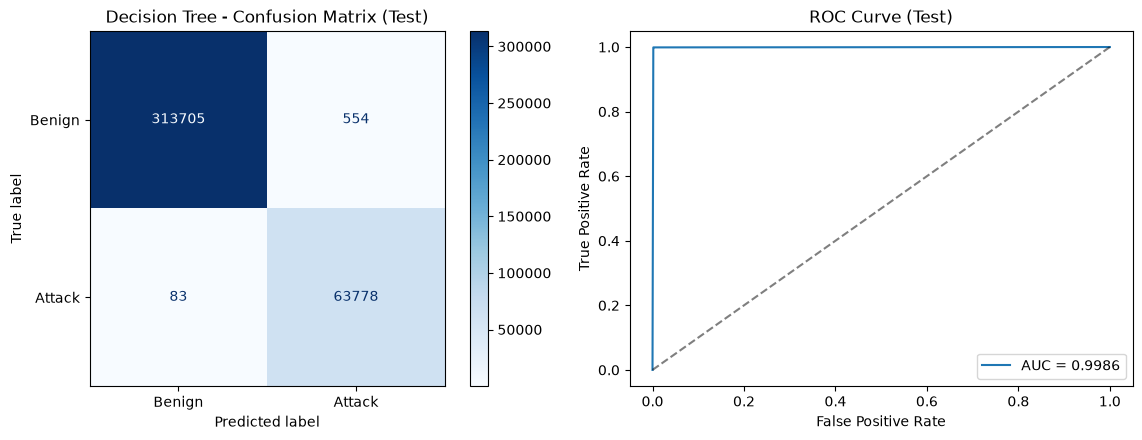

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

cm = confusion_matrix(y_test, test_pred)
ConfusionMatrixDisplay(cm, display_labels=["Benign", "Attack"]).plot(ax=ax[0], cmap="Blues", values_format="d")
ax[0].set_title("Decision Tree - Confusion Matrix (Test)")

fpr, tpr, _ = roc_curve(y_test, test_prob)
ax[1].plot(fpr, tpr, label=f"AUC = {test_m['roc_auc']:.4f}")
ax[1].plot([0, 1], [0, 1], "k--", alpha=0.5)
ax[1].set_xlabel("False Positive Rate"); ax[1].set_ylabel("True Positive Rate")
ax[1].set_title("ROC Curve (Test)"); ax[1].legend()

plt.tight_layout()
plt.savefig(f"{RESULT_DIR}/decision_tree_clean_cm_roc.png", dpi=150)
plt.show()

## Step 6: Top feature importances

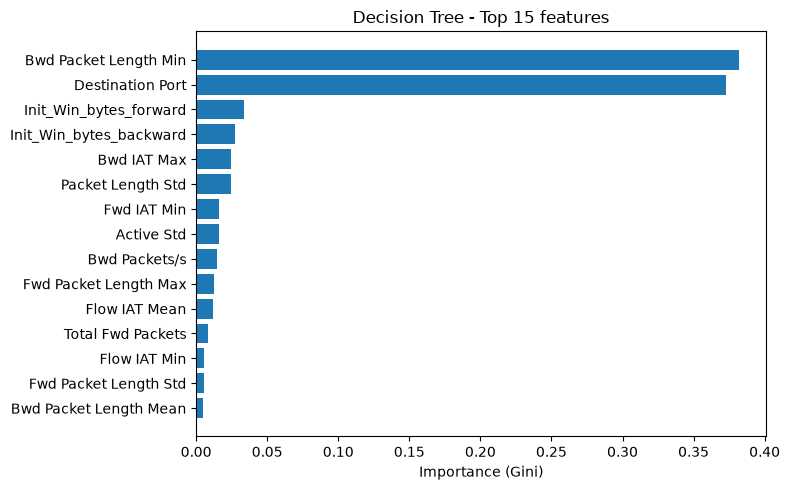

In [7]:
imp = dt.feature_importances_
top = np.argsort(imp)[::-1][:15]

plt.figure(figsize=(8, 5))
plt.barh([feature_names[i] for i in top][::-1], imp[top][::-1])
plt.xlabel("Importance (Gini)")
plt.title("Decision Tree - Top 15 features")
plt.tight_layout()
plt.savefig(f"{RESULT_DIR}/decision_tree_feature_importance.png", dpi=150)
plt.show()

## Step 7: Save results

In [8]:
with open(f"{RESULT_DIR}/decision_tree_clean_metrics.json", "w") as f:
    json.dump({"validation": val_m, "test": test_m, "train_time_s": train_time,
               "depth": int(dt.get_depth()), "leaves": int(dt.get_n_leaves())}, f, indent=2)
print("Saved:", sorted(os.listdir(RESULT_DIR)))

Saved: ['decision_tree_clean_cm_roc.png', 'decision_tree_clean_metrics.json', 'decision_tree_feature_importance.png', 'logreg_clean_cm_roc.png', 'logreg_clean_metrics.json', 'svm_clean_cm_roc.png', 'svm_clean_metrics.json', 'xgboost_clean_cm_roc.png', 'xgboost_clean_metrics.json', 'xgboost_feature_importance.png']


## Step 8: Compare with the other models trained so far

In [9]:
models = {"LogReg": "logreg_clean_metrics.json", "LinearSVM": "svm_clean_metrics.json",
          "XGBoost": "xgboost_clean_metrics.json", "DecTree": "decision_tree_clean_metrics.json"}
res = {}
for name, fn_ in models.items():
    p = os.path.join(RESULT_DIR, fn_)
    if os.path.exists(p):
        res[name] = json.load(open(p))["test"]

print(f"{'Metric':14s}" + "".join(f"{n:>12s}" for n in res))
for k in keys:
    print(f"{k:14s}" + "".join(f"{res[n][k]:12.4f}" for n in res))

Metric              LogReg   LinearSVM     XGBoost     DecTree
accuracy            0.7908      0.7955      0.9988      0.9983
precision           0.4464      0.4521      0.9931      0.9914
recall              0.9951      0.9938      0.9999      0.9987
f1                  0.6163      0.6215      0.9965      0.9950
specificity         0.7493      0.7553      0.9986      0.9982
fpr                 0.2507      0.2447      0.0014      0.0018
fnr                 0.0049      0.0062      0.0001      0.0013
roc_auc             0.9745      0.9759      1.0000      0.9986


## Optional: limit tree depth to reduce overfitting
If the train accuracy is near 1.0 and noticeably above test accuracy, try `max_depth=10` or `15` and compare. A smaller tree is also easier to explain in the report.

In [ ]:
RUN_DEPTH_SWEEP = False

if RUN_DEPTH_SWEEP:
    for d in [5, 10, 15, 20]:
        m = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train, y_train)
        r, _, _ = evaluate(m, X_val, y_val, "validation")
        print(f"depth={d:2d}  val F1={r['f1']:.4f}  val FNR={r['fnr']:.4f}")

## Notes for the report and Phase 3
- A decision tree is **not differentiable**, so FGSM/PGD cannot be applied to it directly. Use a **transfer attack** from a differentiable surrogate (DNN or Logistic Regression), or a black-box attack from the Adversarial Robustness Toolbox.
- Trees split on thresholds, so a small perturbation that moves a feature across a threshold can flip a prediction. This is worth noting when you discuss robustness.
- Compare **FNR** across models: missed attacks are what adversarial evasion will try to increase.